<a href="https://colab.research.google.com/github/SinhaPushkar047/Langgraph/blob/main/Simple_Parallel_Workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [91]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict

In [92]:
class BatsmanState(TypedDict):
  runs: int
  balls: int
  fours: int
  sixes: int

  sr: float
  bpb: float
  bp: float
  summary: str

In [93]:
def cal_sr(state: BatsmanState)->BatsmanState:
  runs=state['runs']
  balls=state['balls']

  sr=(runs/balls)*100

  return {'sr':sr}

In [94]:
def cal_bpb(state:BatsmanState)->BatsmanState:
  balls=state['balls']
  sixes=state['sixes']
  fours=state['fours']

  bpb=balls/(sixes+fours)

  return {'bpb':bpb}

In [95]:
def cal_bp(state:BatsmanState)->BatsmanState:
  runs=state['runs']
  sixes=state['sixes']
  fours=state['fours']

  bp=((sixes*6+fours*4)/runs)*100

  return {'bp':bp}

In [96]:
def summary(state:BatsmanState)->BatsmanState:

  summary=f"""
  Strike Rate:- {state['sr']} \n
  Balls per Boundary:- {state['bpb']} \n
  Boundary Percentage:- {state['bp']}
  """
  summary=summary

  return {'summary':summary}

In [97]:
graph=StateGraph(BatsmanState)

graph.add_node('calculate_sr',cal_sr)
graph.add_node('calculate_bpb',cal_bpb)
graph.add_node('calculate_bp',cal_bp)
graph.add_node('Summary',summary)

graph.add_edge(START,'calculate_sr')
graph.add_edge(START,'calculate_bpb')
graph.add_edge(START,'calculate_bp')

graph.add_edge('calculate_sr','Summary')
graph.add_edge('calculate_bpb','Summary')
graph.add_edge('calculate_bp','Summary')

graph.add_edge('Summary',END)

workflow=graph.compile()

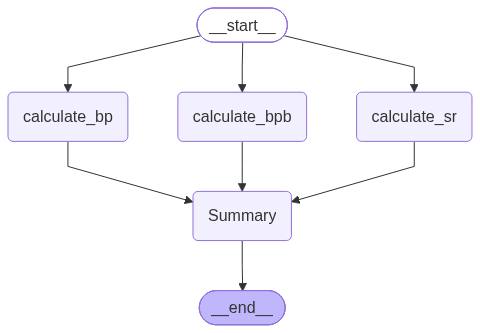

In [98]:
workflow

In [99]:
initial_state={
    'runs':100,
    'balls': 50,
    'fours': 6,
    'sixes': 4
}

In [100]:
workflow.invoke(initial_state)

{'runs': 100,
 'balls': 50,
 'fours': 6,
 'sixes': 4,
 'sr': 200.0,
 'bpb': 5.0,
 'bp': 48.0,
 'summary': '\n  Strike Rate:- 200.0 \n\n  Balls per Boundary:- 5.0 \n\n  Boundary Percentage:- 48.0\n  '}